# Graph Networks for Polymers: The Theory

> **About this notebook, version 1.0.0 (17 November 2026).** The first of five notebooks of the repository *Polymer Neural Nets*. It repeats the algebra of neurons, layers, backpropagation and Adam from the Computational Classnotes notebook *Feedforward Neural Networks* [2], so that it can be read on its own, and extends it to graphs, message passing, symmetry, conservative forces, force matching, integrators and the scaling laws of polymers. Every equation is numbered, every theorem is checked by a code cell, and the same equation numbers are used in the source code (`src/polymer_nn`). Python 3.14 with NumPy, SciPy, SymPy, Matplotlib, PyTorch and PyTorch Geometric; all free and open source.

*From one neuron to an energy-conserving graph network for a polymer chain: the algebra, the symmetries, the physics, and a numerical check of every formula*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="22">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

A polymer is a long chain of beads that pull on their neighbours along the chain and push away any bead that comes too close. Simulating it means computing, again and again, the force on every bead. The force follows from one number, the potential energy E of the whole configuration, as minus its gradient. This notebook builds, one step at a time, a neural network that learns E from examples and gives forces fit for a simulation. Sections 1 and 2 repeat the algebra of the companion notebook *Feedforward Neural Networks* [2]: a neuron, a layer as a matrix product, a network as a chain of layers, the loss, backpropagation by the chain rule, gradient descent and Adam. Each formula is checked against PyTorch, and a small network learns the bond energy of the Kremer–Grest chain. Section 3 explains why a polymer is naturally a graph, and section 4 introduces message passing, the operation of a graph neural network, with a proof that it does not depend on how the beads are numbered. Section 5 states what a physical energy must satisfy: it must stay the same when the chain is moved or turned. It proves that a network which sees only distances has this property and that its forces then turn with the chain. Section 6 writes out the two networks of this repository, a SchNet-style network and an EGNN-style network, with the radial basis functions and the smooth cutoff that keep the energy continuous. Section 7 proves that forces computed as F = −∇E conserve energy in a simulation, and shows a network that predicts forces directly heating a system up. Section 8 explains force matching and the theorem behind coarse-graining. Section 9 covers the integrators, velocity Verlet and the BAOAB Langevin scheme, with their error laws checked numerically. Section 10 covers the scaling laws R_g ∝ N^ν that the learned chains must reproduce: an exact formula for the ideal chain, derived with SymPy, Flory's argument for ν = 3/5, and why pivot Monte Carlo samples the right distribution.

**Keywords:** neuron; SiLU; layer; backpropagation; Adam; universal approximation; graph; message passing; permutation invariance; rotation invariance; equivariance; radial basis; smooth cutoff; SchNet; EGNN; conservative force; energy conservation; force matching; potential of mean force; velocity Verlet; BAOAB; random walk; radius of gyration; Flory exponent; pivot algorithm

Every code cell starts with a comment such as `# c.7` giving its index, and the cells are meant to run in order from c.0. The other notebooks of this repository are *The Data and the Graph* (01), *Reference Simulations and Physics Checks* (02), *Training the Force Fields* (03) and *Learned Dynamics* (04). Numbers in square brackets refer to the list of references at the end; the full bibliography is `docs/REFERENCES.md`.

## Index of equations, figures, tables, theorems and code cells

- Section 1, a neuron, a layer, a network: Eqs. (1.1)–(1.6), Figure 1, Tables 1–2, cells c.1–c.3.
- Section 2, loss, backpropagation, training: Eqs. (2.1)–(2.7), Theorems 1–2, Tables 3–4, Figure 2, cells c.4–c.5.
- Section 3, a polymer as a graph: Eqs. (3.1)–(3.3), Figure 3, Table 5, cell c.6.
- Section 4, message passing: Eqs. (4.1)–(4.4), Theorem 3, Table 6, cell c.7.
- Section 5, symmetry: Eqs. (5.1)–(5.4), Theorems 4–5, Table 7, cell c.8.
- Section 6, the two networks: Eqs. (6.1)–(6.9), Theorems 6–7, Figures 4–5, Table 8, cells c.9–c.10.
- Section 7, conservative forces: Eqs. (7.1)–(7.3), Theorem 8, Figure 6, cell c.11.
- Section 8, force matching: Eqs. (8.1)–(8.4), Theorem 9, Figure 7, cell c.12.
- Section 9, integrators: Eqs. (9.1)–(9.4), Theorem 10, Figure 8, Table 9, cells c.13–c.14.
- Section 10, polymer scaling: Eqs. (10.1)–(10.7), Theorems 11a and 11, Figure 9, Tables 10–11, cells c.15–c.17.
- Appendix A, the formulas in one place.

## 0. Settings

Cell c.0 makes the notebook run in any Jupyter. It installs missing libraries with pip, finds the repository folder (or, if this notebook was opened on its own, downloads the repository's code and data once from GitHub into `~/polymer-neural-nets`), and sets the style of every figure and table: font size 14 in figures, 10 in tables, and widths that print well on A4. The helpers `table`, `nform` and `sci` are in `src/polymer_nn/nbtools.py`.

In [1]:
# c.0
# Setup. This cell makes the notebook run in any Jupyter, three ways:
#  (1) inside the repository folder (e.g. `uv run jupyter lab`, or `pip install -r requirements.txt` then `jupyter lab`);
#  (2) in any Python environment: libraries that are missing are installed with pip into this kernel;
#  (3) as a single notebook file on its own: the code and data of the repository are downloaded once from
#      GitHub into the folder polymer-neural-nets in your home folder.
import importlib.util, subprocess, sys, io, zipfile, urllib.request, warnings
from pathlib import Path
warnings.filterwarnings("ignore")   # library notices (tqdm, TorchScript) are not part of the results
NEED = {"numpy": "numpy", "scipy": "scipy", "sympy": "sympy", "matplotlib": "matplotlib", "torch": "torch",
        "torch_geometric": "torch-geometric", "openmm": "openmm", "IPython": "ipython"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if sys.platform == "emscripten":                                 # JupyterLite / Pyodide: Python inside the web page
    raise SystemExit("\n".join([
        "This Jupyter runs Python inside the web browser (JupyterLite / Pyodide, WebAssembly).",
        "PyTorch and OpenMM are not available there, and nothing can be installed with pip, so this notebook",
        "cannot run in it. The saved results are still shown in the notebook, and in the .md and .pdf editions.",
        "",
        "To run it, use Jupyter with a real Python on your computer. It also opens in the browser. In a terminal:",
        "  1. install uv (once):   curl -LsSf https://astral.sh/uv/install.sh | sh",
        "                          (Windows PowerShell: irm https://astral.sh/uv/install.ps1 | iex)",
        "  2. get the repository:  git clone https://github.com/lossofgenerality/polymer-neural-nets",
        "                          cd polymer-neural-nets",
        "  3. install and start:   uv sync   then   uv run jupyter notebook",
        "Then open this notebook in the Jupyter tab that appears and choose Kernel → Restart Kernel and Run All Cells."]))
def install(pkgs):
    """Install pkgs into the Python of this kernel; try pip, then uv; explain clearly if neither works."""
    import shutil
    tries = [[sys.executable, "-m", "pip", "install", *pkgs]]
    if shutil.which("uv"):
        tries.append(["uv", "pip", "install", "--python", sys.executable, *pkgs])
    errors = []
    for cmd in tries:
        try:
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode == 0:
                importlib.invalidate_caches(); return
            errors.append(f"{' '.join(cmd[:4])} …: exit code {r.returncode}\n{(r.stderr or r.stdout)[-1200:]}")
        except OSError as e:
            errors.append(f"{' '.join(cmd[:4])} …: could not be started ({e})")
    managed = any("externally-managed" in e for e in errors)
    raise SystemExit("\n".join([
        "Could not install " + ", ".join(pkgs) + " into the Python of this Jupyter kernel:", "    " + sys.executable, "",
        *errors, "",
        "Fix it in a terminal, in the folder of this repository, with one of these, then restart the kernel:",
        "  (a) uv:   uv sync   and then   uv run jupyter notebook      (uses the exact versions of uv.lock)",
        "  (b) venv: python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter notebook",
        "            (Windows: .venv\\Scripts\\activate)",
        f"  (c) this kernel's Python: \"{sys.executable}\" -m pip install " + " ".join(pkgs),
        "This Python is managed by the system or Homebrew and refuses installs: use (a) or (b)." if managed else ""]))
if missing:
    print("installing", ", ".join(missing), "(first run only; torch is large) ...")
    install(missing)
def find_repo():
    for q in [Path.cwd(), *Path.cwd().parents]:                  # (1) this notebook is inside the repository
        if (q / "src" / "polymer_nn").is_dir() and (q / "data").is_dir():
            return q
    home = Path.home() / "polymer-neural-nets"                    # (3) download it once
    if not (home / "src" / "polymer_nn").is_dir():
        url = "https://github.com/lossofgenerality/polymer-neural-nets/archive/refs/heads/main.zip"
        print("downloading the repository (code, data, models) from", url)
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            top = z.namelist()[0].split("/")[0]
            for m in z.infolist():
                rel = m.filename[len(top) + 1:]
                if rel and not m.is_dir():
                    (home / rel).parent.mkdir(parents=True, exist_ok=True)
                    (home / rel).write_bytes(z.read(m))
    return home
ROOT = find_repo()
sys.path.insert(0, str(ROOT / "src"))                             # use the repository's polymer_nn
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from polymer_nn import nbtools as nb
from polymer_nn.nbtools import table, nform, sci, savefig, figFont, wFull, wHalf, red, blue, green, orange, grey
nb.setup(threads=2)                 # plot style and 2 CPU threads; figures are saved in ./figures
DATA = ROOT / "data"                # the reference data made by scripts/generate_data.py
torch.manual_seed(0); rng = np.random.default_rng(0)
print("repository folder:", ROOT.name, "| Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__)

repository folder: polymer-neural-nets | Python 3.14.6 | torch 2.15.0+cu132 | numpy 2.5.5


## 1. A neuron, a layer, a network

### 1.1 One neuron

A neuron takes n numbers x = (x₁, …, xₙ), multiplies each by a weight, adds a bias and passes the result through an *activation function* φ:

$$
z = w \cdot x + b = \sum_{k=1}^{n} w_k x_k + b , \qquad a = \varphi(z) \tag{1.1}
$$

The weights $w_k$ and the bias $b$ are the numbers that training will adjust. Without φ, any chain of neurons would be one linear map, and a linear map cannot represent the curved energy landscape of a molecule. The classic activation is the logistic sigmoid σ, the S-shaped function of *S Shape Functions Theory* [1]. Our networks use its smooth relative, the *sigmoid-weighted linear unit* SiLU [elfwing2018]:

$$
\sigma(z) = \frac{1}{1 + e^{-z}} , \qquad \mathrm{SiLU}(z) = z \, \sigma(z) \tag{1.2}
$$

Their derivatives are needed for backpropagation (section 2) and, because the forces are derivatives of the energy, for the forces as well:

$$
\sigma'(z) = \sigma(z)\,\bigl(1 - \sigma(z)\bigr) , \qquad \mathrm{SiLU}'(z) = \sigma(z) + z\,\sigma(z)\,\bigl(1 - \sigma(z)\bigr) \tag{1.3}
$$

Why SiLU and not σ or ReLU = max(0, z)? Forces are first derivatives of the network and training uses second derivatives (section 2.4). ReLU has a kink at 0, so its second derivative is zero almost everywhere and undefined at 0. Then the force would jump and training would get no signal through it. SiLU is smooth (infinitely differentiable) and, unlike σ, does not saturate for large positive z. Cell c.1 checks Eq. (1.3) against finite differences and draws Figure 1.

function,"max |formula − finite difference| on [−6, 6]"
σ′(z) = σ(1 − σ),1.4 × 10⁻¹¹
SiLU′(z) = σ + zσ(1 − σ),1.4 × 10⁻¹⁰
torch.nn.SiLU vs Eq. (1.2),8.9 × 10⁻¹⁶


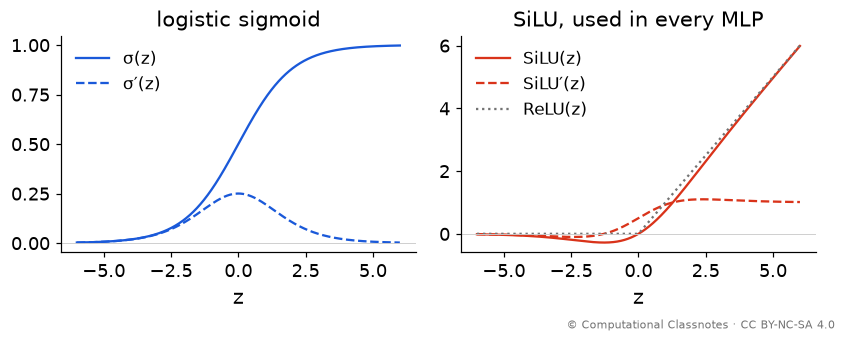

In [2]:
# c.1
# Eq. (1.2) and its derivatives Eq. (1.3), checked by central finite differences
sigma = lambda z: 1 / (1 + np.exp(-z))
silu = lambda z: z * sigma(z)
dsigma = lambda z: sigma(z) * (1 - sigma(z))
dsilu = lambda z: sigma(z) + z * sigma(z) * (1 - sigma(z))
z = np.linspace(-6, 6, 1201); h = 1e-5
fd = lambda f: (f(z + h) - f(z - h)) / (2 * h)       # central difference, error O(h^2)
table([["function", "max |formula − finite difference| on [−6, 6]"],
       ["σ′(z) = σ(1 − σ)", sci(np.abs(dsigma(z) - fd(sigma)).max())],
       ["SiLU′(z) = σ + zσ(1 − σ)", sci(np.abs(dsilu(z) - fd(silu)).max())],
       ["torch.nn.SiLU vs Eq. (1.2)", sci(np.abs(torch.nn.SiLU()(torch.tensor(z)).numpy() - silu(z)).max())]],
      "Table 1. The activation and its derivative, Eqs. (1.2)–(1.3)")
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.25, wHalf * 1.05))
ax[0].plot(z, sigma(z), color=blue, label="σ(z)"); ax[0].plot(z, dsigma(z), "--", color=blue, label="σ′(z)")
ax[1].plot(z, silu(z), color=red, label="SiLU(z)"); ax[1].plot(z, dsilu(z), "--", color=red, label="SiLU′(z)")
ax[1].plot(z, np.maximum(z, 0), ":", color=grey, label="ReLU(z)")
for a in ax: a.set_xlabel("z"); a.legend(); a.axhline(0, color="0.8", lw=0.6)
ax[0].set_title("logistic sigmoid"); ax[1].set_title("SiLU, used in every MLP")
fig.tight_layout(); savefig(fig, "fig1_activations"); plt.show()

*Figure 1. Left: the logistic sigmoid and its derivative. Right: SiLU, its derivative, and ReLU for comparison. SiLU is close to ReLU for large |z| but smooth at 0, so the forces of the network (first derivatives) and the training signal through them (second derivatives) are smooth.*

### 1.2 A layer is one matrix product

m neurons that read the same input form a *layer*. Stacking their weight vectors as the rows of an m × n matrix W and their biases in a vector b ∈ ℝ^m gives

$$
z = W x + b , \qquad a = \varphi(z) \quad (\varphi \text{ applied to every component}) \tag{1.4}
$$

For M inputs at once, written as the rows of an M × n matrix X, the whole batch is one matrix–matrix product, with b added to every row:

$$
Z = X W^{\mathsf T} + \mathbf 1\, b^{\mathsf T} , \qquad A = \varphi(Z) \tag{1.5}
$$

This is exactly what `torch.nn.Linear` computes. In our graph networks the "batch" is the set of all beads, or of all edges: the same small layer is applied to every bead (or edge) of the chain at once.

### 1.3 A network is a chain of layers

A multilayer perceptron (MLP) applies layers one after another, the output of one being the input of the next:

$$
a^{0} = x , \qquad a^{l} = \varphi\bigl(W^{l} a^{l-1} + b^{l}\bigr) \quad (l = 1, \dots, L-1) , \qquad y = W^{L} a^{L-1} + b^{L} \tag{1.6}
$$

The last layer has no activation, so that the output can be any real number, for example an energy. `polymer_nn.models.mlp(n, H, m)` builds exactly Eq. (1.6) with one hidden layer of H SiLU neurons. Every MLP inside the graph networks of section 6 is of this kind. Cell c.2 checks Eqs. (1.4)–(1.6) against PyTorch, layer by layer, and cell c.3 shows why everything is done in batches: one matrix product for all inputs is far faster than a loop over them.

In [3]:
# c.2
# Eqs. (1.4)-(1.6) by hand in NumPy, compared with polymer_nn.models.mlp (PyTorch)
from polymer_nn.models import mlp
torch.manual_seed(1)
net = mlp(3, 8, 1).double()                       # Linear(3->8), SiLU, Linear(8->1)
W1, b1 = net[0].weight.detach().numpy(), net[0].bias.detach().numpy()   # W is 8 x 3: outputs x inputs
W2, b2 = net[2].weight.detach().numpy(), net[2].bias.detach().numpy()
X = rng.normal(size=(5, 3))                       # M = 5 inputs as rows
A1 = silu(X @ W1.T + b1)                          # Eq. (1.5) with phi = SiLU
Y = A1 @ W2.T + b2                                # Eq. (1.6): no activation on the last layer
Y_torch = net(torch.tensor(X)).detach().numpy()
loop = np.array([W2 @ silu(W1 @ x + b1) + b2 for x in X])     # Eq. (1.4), one input at a time
table([["quantity", "value"], ["shapes W¹, b¹, W², b²", f"{W1.shape}, {b1.shape}, {W2.shape}, {b2.shape}"],
       ["number of weights and biases", 8 * 3 + 8 + 1 * 8 + 1],
       ["max |NumPy batch − PyTorch|", sci(np.abs(Y - Y_torch).max())],
       ["max |NumPy loop − NumPy batch|", sci(np.abs(loop - Y).max())]], "Table 2. A 3-8-1 MLP by hand and in PyTorch")

quantity,value
"shapes W¹, b¹, W², b²","(8, 3), (8,), (1, 8), (1,)"
number of weights and biases,41
max |NumPy batch − PyTorch|,5.6 × 10⁻¹⁷
max |NumPy loop − NumPy batch|,0


In [4]:
# c.3
# why batches: the same layer for 20 000 inputs, as a loop of Eq. (1.4) and as one product, Eq. (1.5)
Xbig = rng.normal(size=(20000, 3))
t0 = time.perf_counter(); out_loop = np.array([W1 @ x + b1 for x in Xbig]); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); out_batch = Xbig @ W1.T + b1; t_batch = time.perf_counter() - t0
print(f"loop {t_loop*1e3:.1f} ms, one matrix product {t_batch*1e3:.2f} ms: {t_loop/t_batch:.0f} times faster; "
      f"max difference {np.abs(out_loop - out_batch).max():.1e}")

loop 33.2 ms, one matrix product 1.31 ms: 25 times faster; max difference 4.4e-16


## 2. Loss, backpropagation and training

### 2.1 The loss

Training adjusts all weights θ = (W¹, b¹, …, W^L, b^L) so that the network output ŷ(x; θ) is close to the target y for every example. The distance is measured by a *loss*; here, the mean squared error over M examples:

$$
L(\theta) = \frac{1}{M} \sum_{s=1}^{M} \bigl| \hat y(x_s; \theta) - y_s \bigr|^{2} \tag{2.1}
$$

For the force fields of this repository the examples are configurations of the chain, and the targets are the forces and the energy computed by OpenMM (section 8, and `polymer_nn.train`, Eq. (T1)).

### 2.2 Backpropagation

Gradient descent needs ∂L/∂θ for every weight. Write δ^l = ∂L/∂z^l for the derivative of the loss with respect to the weighted sums of layer l (one example; for a batch, average over examples). Then

$$
\delta^{L} = \frac{\partial L}{\partial \hat y} \quad (\text{last layer, no activation}) \tag{2.2}
$$

$$
\delta^{l} = \bigl( (W^{l+1})^{\mathsf T} \delta^{l+1} \bigr) \odot \varphi'(z^{l}) \tag{2.3}
$$

$$
\frac{\partial L}{\partial W^{l}} = \delta^{l} \, (a^{l-1})^{\mathsf T} , \qquad \frac{\partial L}{\partial b^{l}} = \delta^{l} \tag{2.4}
$$

where ⊙ is the component-wise product.

**Theorem 1 (backpropagation [rumelhart1986]).** Eqs. (2.2)–(2.4) give the exact gradient of L, for every layer, at the cost of about one extra pass through the network.

*Proof.* $z^{l+1} = W^{l+1} \varphi(z^l) + b^{l+1}$ depends on $z^l$ only through $a^l = \varphi(z^l)$. The chain rule gives $\partial L/\partial z^l_k = \sum_m (\partial L/\partial z^{l+1}_m)(\partial z^{l+1}_m/\partial a^l_k)(d a^l_k/d z^l_k) = \sum_m \delta^{l+1}_m W^{l+1}_{mk}\, \varphi'(z^l_k)$, which is Eq. (2.3). Since $z^l_k = \sum_j W^l_{kj} a^{l-1}_j + b^l_k$, we have $\partial z^l_k/\partial W^l_{kj} = a^{l-1}_j$ and $\partial z^l_k/\partial b^l_k = 1$, which gives Eq. (2.4). Each $\delta^l$ is computed once, from $\delta^{l+1}$, so the cost is that of one backward pass. ∎

The same chain rule, applied by PyTorch's automatic differentiation, gives the forces of section 7: there we differentiate the energy with respect to the *inputs* (the bead positions) instead of the weights.

### 2.3 Gradient descent and Adam

Gradient descent moves every weight a small step against its derivative, with learning rate η:

$$
\theta \leftarrow \theta - \eta \, \nabla_\theta L \tag{2.5}
$$

Adam [kingma2015] keeps running averages of the gradient g and of its square. It steps by about η in every direction, whatever the scale of that weight's gradient (t counts steps; β₁ = 0.9, β₂ = 0.999, ϵ = 10⁻⁸):

$$
m \leftarrow \beta_1 m + (1-\beta_1) g , \quad v \leftarrow \beta_2 v + (1-\beta_2) g^{2} , \quad \theta \leftarrow \theta - \eta \, \frac{m/(1-\beta_1^{t})}{\sqrt{v/(1-\beta_2^{t})} + \epsilon} \tag{2.6}
$$

Cell c.4 programs Eqs. (2.2)–(2.4) and checks them against finite differences and against PyTorch's autograd (Table 3).

In [5]:
# c.4
# backpropagation, Eqs. (2.2)-(2.4), for the 3-8-1 network of c.2 and the loss of Eq. (2.1)
Yt = rng.normal(size=(5, 1))                      # targets
def loss_np(W1, b1, W2, b2):
    return np.mean((silu(X @ W1.T + b1) @ W2.T + b2 - Yt) ** 2)
Z1 = X @ W1.T + b1; A1 = silu(Z1); Yh = A1 @ W2.T + b2
d2 = 2 * (Yh - Yt) / len(X)                       # Eq. (2.2), averaged over the batch: M x 1
d1 = (d2 @ W2) * dsilu(Z1)                        # Eq. (2.3): M x 8
gW2, gb2 = d2.T @ A1, d2.sum(0)                   # Eq. (2.4), summed over the examples
gW1, gb1 = d1.T @ X, d1.sum(0)
# finite differences for every one of the 41 numbers
def fd_grad(i, P):
    out = np.zeros_like(P[i])
    for k in np.ndindex(P[i].shape):
        Pp = [p.copy() for p in P]; Pm = [p.copy() for p in P]
        Pp[i][k] += 1e-6; Pm[i][k] -= 1e-6
        out[k] = (loss_np(*Pp) - loss_np(*Pm)) / 2e-6
    return out
P = [W1, b1, W2, b2]
fdg = [fd_grad(i, P) for i in range(4)]
# PyTorch autograd on the same network
lt = torch.mean((net(torch.tensor(X)) - torch.tensor(Yt)) ** 2); lt.backward()
tg = [net[0].weight.grad, net[0].bias.grad, net[2].weight.grad, net[2].bias.grad]
names = ["∂L/∂W¹ (8 × 3)", "∂L/∂b¹ (8)", "∂L/∂W² (1 × 8)", "∂L/∂b² (1)"]
table([["gradient", "max |backprop − finite diff.|", "max |backprop − autograd|"]] +
      [[n, sci(np.abs(g - f).max()), sci(np.abs(g - t.numpy()).max())] for n, g, f, t in zip(names, [gW1, gb1, gW2, gb2], fdg, tg)],
      "Table 3. Backpropagation, Eqs. (2.2)–(2.4), checked")

gradient,max |backprop − finite diff.|,max |backprop − autograd|
∂L/∂W¹ (8 × 3),1 × 10⁻¹⁰,5.6 × 10⁻¹⁷
∂L/∂b¹ (8),8.2 × 10⁻¹¹,2.8 × 10⁻¹⁷
∂L/∂W² (1 × 8),9.6 × 10⁻¹¹,1.7 × 10⁻¹⁷
∂L/∂b² (1),1.1 × 10⁻¹¹,1.1 × 10⁻¹⁶


### 2.4 Universal approximation, and a first physical example

**Theorem 2 (universal approximation [cybenko1989]).** Let φ be continuous and not a polynomial (σ and SiLU qualify). For every continuous function f on a closed bounded set K ⊂ ℝⁿ and every ε > 0 there is a network with one hidden layer, ŷ(x) = Σ_k c_k φ(w_k·x + b_k), with |ŷ(x) − f(x)| < ε on all of K.

The proof for sigmoids is in *S Shape Functions Theory* [1]; the extension to any non-polynomial φ is due to Leshno, Lin, Pinkus and Schocken (1993). The theorem says that a large enough network *can* represent the energy of a polymer. It does not say how to find the weights, and that is what training does.

A first example in the language of this repository: the energy of one Kremer–Grest bond as a function of its length r, the FENE spring plus the WCA repulsion (Eqs. (S1)–(S2) of `polymer_nn.sim`, repeated in section 10.4):

$$
U(r) = -\tfrac12 k R_0^2 \ln\!\Bigl(1 - \tfrac{r^2}{R_0^2}\Bigr) + 4\Bigl[\Bigl(\tfrac1r\Bigr)^{12} - \Bigl(\tfrac1r\Bigr)^{6}\Bigr] + 1 , \qquad k = 30,\; R_0 = 1.5 . \tag{2.7}
$$

Cell c.5 trains a 1-32-1 SiLU network on 60 values of U on 0.85 ≤ r ≤ 1.15, the bond lengths that actually occur at k_BT = 1. Inputs and targets are rescaled to order 1 first (and the scaling undone afterwards), which a network needs when the target spans tens of ε. It is trained twice from the same starting weights: once with Adam written by hand from Eq. (2.6), once with `torch.optim.Adam`. After 100 steps the two sets of weights agree to rounding error, which shows that the library does exactly this algebra. (Over thousands of steps, rounding differences of 10⁻¹⁶ grow, as in any long iteration, but both runs reach the same loss.) The learned force −dU/dr is then compared with the exact one.

quantity,value
scaled loss after 4000 steps (Adam by hand),8.1 × 10⁻⁶
scaled loss after 4000 steps (torch.optim.Adam),8.2 × 10⁻⁶
max |weights by hand − weights by torch| after 100 steps,1.3 × 10⁻¹⁵
max |learned − exact energy| (ε),3.3 × 10⁻²
max |learned − exact force| (ε/σ),7.4 × 10⁰
mean |learned − exact force| (ε/σ),5.4 × 10⁻¹
range of the exact force (ε/σ),-84.9 … 284.6


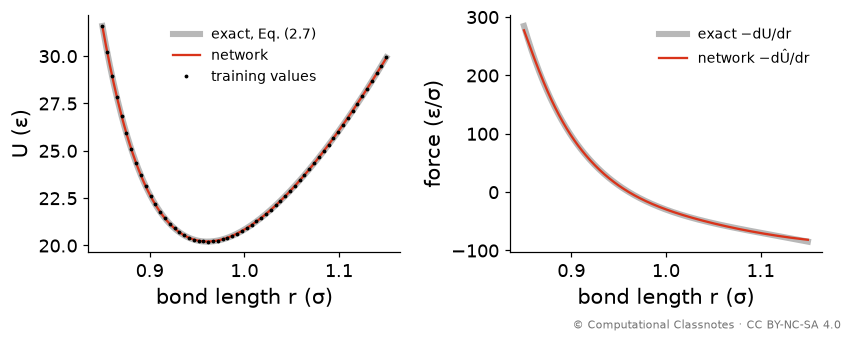

In [6]:
# c.5
# a 1-16-1 network learns the Kremer-Grest bond energy, Eq. (2.7); Adam by hand, Eq. (2.6), vs torch.optim.Adam
def U_bond(r):
    return -0.5 * 30 * 1.5**2 * np.log(1 - (r / 1.5) ** 2) + 4 * (r**-12 - r**-6) + 1
r_tr = np.linspace(0.85, 1.15, 60)[:, None]; U_tr = U_bond(r_tr)
s = lambda r: (r - 1.0) / 0.15                    # inputs scaled to [-1, 1]
mu_U, sd_U = U_tr.mean(), U_tr.std()               # targets scaled to mean 0, spread 1
torch.manual_seed(3); bnet = mlp(1, 32, 1).double(); start = [p.detach().clone() for p in bnet.parameters()]
xt, yt = torch.tensor(s(r_tr)), torch.tensor((U_tr - mu_U) / sd_U)
lr, b1_, b2_, eps, steps = 0.01, 0.9, 0.999, 1e-8, 4000
def reset():
    with torch.no_grad():
        for p, p0 in zip(bnet.parameters(), start): p.copy_(p0)
def adam_by_hand(n):                                   # Eq. (2.6), written out
    reset(); m = [torch.zeros_like(p) for p in bnet.parameters()]; v = [torch.zeros_like(p) for p in bnet.parameters()]
    for t in range(1, n + 1):
        bnet.zero_grad(); L = torch.mean((bnet(xt) - yt) ** 2); L.backward()
        with torch.no_grad():
            for p, mi, vi in zip(bnet.parameters(), m, v):
                g = p.grad
                mi.mul_(b1_).add_((1 - b1_) * g); vi.mul_(b2_).add_((1 - b2_) * g * g)
                p -= lr * (mi / (1 - b1_**t)) / (torch.sqrt(vi / (1 - b2_**t)) + eps)
    return [p.detach().clone() for p in bnet.parameters()], L.item()
def adam_torch(n):                                     # the library optimiser
    reset(); opt = torch.optim.Adam(bnet.parameters(), lr=lr, betas=(b1_, b2_), eps=eps)
    for t in range(n):
        opt.zero_grad(); L = torch.mean((bnet(xt) - yt) ** 2); L.backward(); opt.step()
    return [p.detach().clone() for p in bnet.parameters()], L.item()
wa, _ = adam_by_hand(100); wb, _ = adam_torch(100)
diff100 = max(float((a_ - b_).abs().max()) for a_, b_ in zip(wa, wb))
_, loss_mine = adam_by_hand(steps); _, loss_torch = adam_torch(steps)      # bnet now holds the torch.optim result
# learned force -dU/dr by autograd, compared with the exact force
rr = torch.linspace(0.85, 1.15, 301, dtype=torch.float64)[:, None].requires_grad_(True)
Uh = bnet((rr - 1.0) / 0.15) * sd_U + mu_U; (dU,) = torch.autograd.grad(Uh.sum(), rr)   # undo the target scaling
r_np = rr.detach().numpy().ravel(); F_exact = -(U_bond(r_np + 1e-6) - U_bond(r_np - 1e-6)) / 2e-6
ferr = np.abs(-dU.numpy().ravel() - F_exact)
table([["quantity", "value"], ["scaled loss after 4000 steps (Adam by hand)", sci(loss_mine)],
       ["scaled loss after 4000 steps (torch.optim.Adam)", sci(loss_torch)],
       ["max |weights by hand − weights by torch| after 100 steps", sci(diff100)],
       ["max |learned − exact energy| (ε)", sci(np.abs(Uh.detach().numpy().ravel() - U_bond(r_np)).max())],
       ["max |learned − exact force| (ε/σ)", sci(ferr.max())], ["mean |learned − exact force| (ε/σ)", sci(ferr.mean())],
       ["range of the exact force (ε/σ)", f"{F_exact.min():.1f} … {F_exact.max():.1f}"]], "Table 4. Learning one bond")
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.25, wHalf * 1.05))
ax[0].plot(r_np, U_bond(r_np), color=grey, lw=4, alpha=.5, label="exact, Eq. (2.7)")
ax[0].plot(r_np, Uh.detach().numpy(), color=red, label="network"); ax[0].plot(r_tr, U_tr, ".", color="k", ms=3, label="training values")
ax[1].plot(r_np, F_exact, color=grey, lw=4, alpha=.5, label="exact −dU/dr"); ax[1].plot(r_np, -dU.numpy(), color=red, label="network −dÛ/dr")
ax[0].set(xlabel="bond length r (σ)", ylabel="U (ε)"); ax[1].set(xlabel="bond length r (σ)", ylabel="force (ε/σ)")
for a in ax: a.legend(fontsize=9)
fig.tight_layout(); savefig(fig, "fig2_bond"); plt.show()

*Figure 2. A 1-32-1 network learns the Kremer–Grest bond energy (left) from 60 values. Its force (right), obtained by differentiating the network, follows the exact force to a few per cent of its range although no force was used in training; the largest errors are at the steep wall, where training values are sparse. Training on forces as well, as the graph networks do, removes most of that error. This is a one-dimensional version of what the graph networks do for a whole chain.*

## 3. A polymer as a graph

A configuration of a chain of N beads is a list of N positions x_i ∈ ℝ³. One could flatten it into a vector of 3N numbers and give it to an MLP, but that would be wrong in three ways:

1. **Size:** the MLP would accept only one chain length N.
2. **Numbering:** the chain read from the other end, x_N, …, x_1, is the same molecule. A flat MLP would see different inputs and give a different energy.
3. **Space:** moving or turning the chain does not change its energy, but it changes all 3N numbers.

A *graph* removes the first two problems at once, and section 5 removes the third. A graph is a set of nodes V and a set of directed edges E ⊆ V × V:

$$
G = (V, E) , \qquad V = \{0, 1, \dots, N-1\} , \qquad (j \to i) \in E \tag{3.1}
$$

Each node i carries a position x_i and a type z_i (0 for the two chain ends, 1 for interior beads); each edge carries a type τ_ij. For a polymer the edges are the bonds along the chain, plus every pair of beads closer than a cutoff r_c, because those are the pairs that interact:

$$
E = \underbrace{\{(i, i \pm 1)\}}_{\tau = 1,\ \text{bonds}} \ \cup \ \underbrace{\{(i, j) : |i - j| \ge 2,\ r_{ij} < r_c\}}_{\tau = 0,\ \text{non-bonded neighbours}} , \qquad r_{ij} = |x_i - x_j| \tag{3.2}
$$

Every edge is stored in both directions, so that information can flow both ways. In PyTorch Geometric [fey2019] the edges are the two rows of an integer array `edge_index` of shape 2 × |E|: sources j in row 0, targets i in row 1 (`polymer_nn.graph`). The *neighbourhood* of i is

$$
\mathcal N(i) = \{ j : (j \to i) \in E \} \tag{3.3}
$$

With a cutoff, |𝒩(i)| stays small (a handful of beads) however long the chain, so the cost of the network grows linearly with N. Cell c.6 builds the graph of a small folded chain, in which beads 0 and 5 are within the cutoff, and draws it with its symbols (Figure 3).

edge k,j → i,type τ_ij,r_ij (σ)
0,0 → 1,bond,0.970
1,1 → 2,bond,0.972
2,2 → 3,bond,0.975
3,3 → 4,bond,0.971
4,4 → 5,bond,0.971
5,1 → 0,bond,0.970
6,2 → 1,bond,0.972
7,3 → 2,bond,0.975
8,4 → 3,bond,0.971
9,5 → 4,bond,0.971


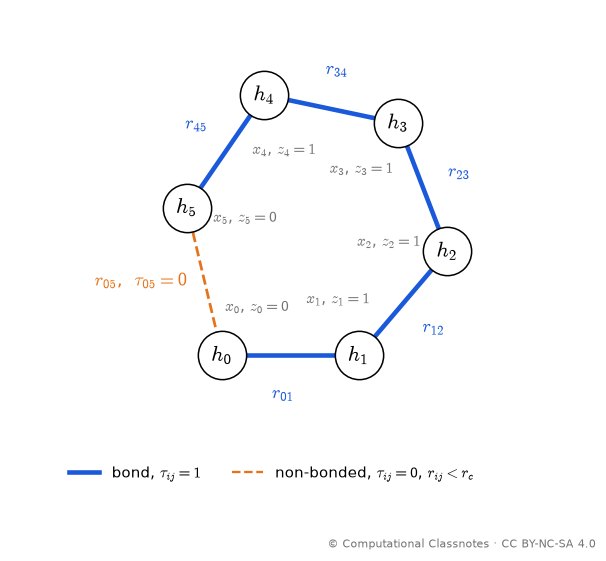

In [7]:
# c.6
# the graph of a 6-bead chain folded so that its ends touch, Eq. (3.2)
from polymer_nn.graph import to_data
xs = np.array([[0, 0, 0], [0.97, 0, 0], [1.6, 0.74, 0], [1.25, 1.65, 0], [0.3, 1.85, 0], [-0.25, 1.05, 0]], float)
g = to_data(xs, cutoff=1.5)
src, dst = g.edge_index.numpy(); et = g.edge_type.numpy()
rij = np.linalg.norm(xs[src] - xs[dst], axis=1)
rows = [["edge k", "j → i", "type τ_ij", "r_ij (σ)"]] + [[k, f"{j} → {i}", "bond" if t else "non-bonded", f"{r:.3f}"]
        for k, (j, i, t, r) in enumerate(zip(src, dst, et, rij))]
table(rows, f"Table 5. The edges of the folded 6-bead chain: {int(et.sum())} bonded, {int((et == 0).sum())} non-bonded (r_c = 1.5 σ)")
fig, ax = plt.subplots(figsize=(wFull * 1.0, wFull * 0.95))
cen = xs[:, :2].mean(0)
def out(p, d):                                    # a point moved by d away from the centre of the ring
    u = p - cen; return p + d * u / np.linalg.norm(u)
for j, i, t in zip(src, dst, et):
    if j < i:  # draw each pair once
        ax.plot(*xs[[j, i], :2].T, color=blue if t else orange, lw=3 if t else 1.8, ls="-" if t else "--", zorder=1)
        mid = xs[[i, j], :2].mean(0)
        lab = rf"$r_{{{j}{i}}}$" + ("" if t else r",  $\tau_{05}=0$")
        ax.text(*(out(mid, 0.28) if t else mid + [-0.12, 0.0]), lab, fontsize=12, color=blue if t else orange, ha="center" if t else "right", va="center")
for i, (x, y, _) in enumerate(xs):
    ax.scatter(x, y, s=1000, color="white", edgecolor="k", zorder=2)
    ax.text(x, y, rf"$h_{i}$", ha="center", va="center", fontsize=14, zorder=3)
    q = out(np.array([x, y]), -0.42)
    ax.text(*q, rf"$x_{i}$, $z_{i}={g.z[i].item()}$", ha="center", va="center", fontsize=10, color=grey)
ax.plot([], [], color=blue, lw=3, label=r"bond, $\tau_{ij}=1$"); ax.plot([], [], color=orange, ls="--", label=r"non-bonded, $\tau_{ij}=0$, $r_{ij}<r_c$")
ax.set_xlim(-1.5, 2.2); ax.set_ylim(-0.75, 2.45); ax.set_aspect("equal"); ax.axis("off")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, fontsize=10)
savefig(fig, "fig3_graph"); plt.show()

*Figure 3. A folded 6-bead chain as a graph. Each node i holds a position x_i, a type z_i (0 = end bead) and a feature vector h_i that the network will update; each edge holds a distance r_ij and a type τ_ij. Bonds (blue) are always edges; beads 0 and 5 are not bonded but closer than r_c = 1.5 σ, so they get a non-bonded edge (orange). Every line stands for two directed edges, j → i and i → j.*

## 4. Message passing

A graph neural network keeps a feature vector h_i ∈ ℝ^H on every node and updates all of them in *layers*. In layer t every edge j → i computes a message, every node adds up the messages it receives, and every node updates its features [gilmer2017]:

$$
m_{ij}^{(t)} = M_t\bigl(h_i^{(t)}, h_j^{(t)}, e_{ij}\bigr) \tag{4.1}
$$

$$
\bar m_i^{(t)} = \sum_{j \in \mathcal N(i)} m_{ij}^{(t)} \tag{4.2}
$$

$$
h_i^{(t+1)} = U_t\bigl(h_i^{(t)}, \bar m_i^{(t)}\bigr) \tag{4.3}
$$

After T layers a *readout* turns the node features into the output; for an energy, a sum of per-node terms:

$$
E = \sum_{i \in V} \varepsilon_i , \qquad \varepsilon_i = R\bigl(h_i^{(T)}\bigr) \tag{4.4}
$$

M_t, U_t and R are small MLPs (Eq. (1.6)) whose weights are shared by all edges and all nodes. The same few thousand weights therefore serve a chain of 10 beads or of 10⁶ beads. After T layers, h_i depends on every bead within T edges of i, so with T = 3 and r_c = 1.5 σ each bead "sees" a neighbourhood of a few σ.

**Theorem 3 (permutation invariance).** Number the beads differently, i.e. apply a permutation π to the node indices of V, E and all node data. Then every $h_i$ is carried to $h_{\pi(i)}$, and E of Eq. (4.4) does not change.

*Proof.* By induction on t. Write $h'$ for the features of the renumbered graph and suppose $h'^{(t)}_{\pi(i)} = h^{(t)}_i$ for all i. The message on the renamed edge π(j) → π(i) equals $m^{(t)}_{ij}$, because $M_t$ sees the same arguments. The renamed neighbourhood of π(i) is π(𝒩(i)), and a sum does not depend on the order of its terms, so Eq. (4.2) gives the same sum and Eq. (4.3) the same $h^{(t+1)}$. The final sum, Eq. (4.4), runs over the same set of terms. ∎

The theorem needs an aggregation that ignores order, a sum, mean or maximum; a sum keeps the energy *extensive* (proportional to N for a long chain). Reading the chain from the other end is such a permutation, i ↦ N − 1 − i; it maps bonds to bonds and end beads to end beads. Cell c.7 writes one interaction layer of `InvariantGNN` (Eqs. (6.3)–(6.5) below) by hand from Eqs. (4.1)–(4.3), checks it against the library layer, and checks Theorem 3.

In [8]:
# c.7
# one message-passing layer written out from Eqs. (4.1)-(4.3), compared with polymer_nn.models.CFConv
from polymer_nn.models import InvariantGNN, edge_envelope
torch.manual_seed(5)
inv = InvariantGNN(hidden=16, layers=2).double().eval()
pos = torch.tensor(xs)
srcT, dstT = g.edge_index
r = (pos[srcT] - pos[dstT]).norm(dim=-1)
rbf = inv.rbf(r); env = edge_envelope(r, g.edge_type, inv.cutoff)
h0 = inv.embed(g.z)                                                    # h^(0) from the bead types
conv = inv.convs[0]
onehot = torch.nn.functional.one_hot(g.edge_type, 2).double()
W = conv.filter(torch.cat([rbf, onehot], -1)) * env[:, None]          # one filter per edge
m = conv.lin_in(h0)[srcT] * W                                          # Eq. (4.1): message on every edge j -> i
mbar = torch.zeros_like(h0).index_add_(0, dstT, m)                     # Eq. (4.2): sum at every target i
h1_hand = h0 + conv.update_mlp(mbar)                                   # Eq. (4.3)
h1_lib = conv(h0, g.edge_index, rbf, g.edge_type, env)
# Theorem 3: number the beads backwards and compare energies and forces
def energy_of(x):
    d = to_data(x); d.pos = torch.tensor(x, dtype=torch.float64)
    e, f = inv(d); return float(e.detach()), f.detach().numpy()
Ea, Fa = energy_of(xs); Eb, Fb = energy_of(xs[::-1].copy())
table([["check", "value"], ["max |h¹ by hand − h¹ from CFConv|", sci(float((h1_hand - h1_lib).abs().max()))],
       ["message tensor m_ij: edges × channels", str(tuple(m.shape))],
       ["E of the chain (random weights)", nform(Ea, 8)], ["E of the chain numbered backwards", nform(Eb, 8)],
       ["max |F_i − F′_{N−1−i}|", sci(np.abs(Fa[::-1] - Fb).max())]],
      "Table 6. Message passing by hand, and Theorem 3")

check,value
max |h¹ by hand − h¹ from CFConv|,0
message tensor m_ij: edges × channels,"(12, 16)"
E of the chain (random weights),1.9165767
E of the chain numbered backwards,1.9165767
max |F_i − F′_{N−1−i}|,0


## 5. Symmetry: what a physical energy must not see

Moving the whole chain by a vector t, turning it by a rotation matrix R (Rᵀ R = 1, det R = 1), or reflecting it, changes every position but not the physics:

$$
x_i \mapsto R x_i + t \quad \text{for all } i \tag{5.1}
$$

These maps form the Euclidean group E(3) (with reflections, det R = −1). A physical energy must be *invariant*,

$$
E(R x_1 + t, \dots, R x_N + t) = E(x_1, \dots, x_N) \tag{5.2}
$$

and the forces must be *equivariant*, turning with the chain:

$$
F_i(R x + t) = R \, F_i(x) \tag{5.3}
$$

**Theorem 4 (distances are enough).** If E depends on the positions only through the distances r_ij = |x_i − x_j|, then E is E(3)-invariant, Eq. (5.2).

*Proof.* |(R x_i + t) − (R x_j + t)| = |R (x_i − x_j)| = |x_i − x_j|, because R preserves lengths. Every input of E is unchanged, so E is unchanged. ∎

Both networks of this repository satisfy the hypothesis: `InvariantGNN` uses only r_ij and the types; `EquivariantGNN` also moves auxiliary vectors, but only in a way that keeps its features invariant (Theorem 7).

**Theorem 5 (forces of an invariant energy are equivariant).** If E satisfies Eq. (5.2) and $F_i = -\nabla_{x_i} E$, then F satisfies Eq. (5.3), and the total force and total torque vanish:

$$
\sum_i F_i = 0 , \qquad \sum_i x_i \times F_i = 0 \tag{5.4}
$$

*Proof.* Differentiate E(Rx + t) = E(x) with respect to x_i. The chain rule gives Rᵀ (∇_i E)(Rx + t) = ∇_i E(x), so (∇_i E)(Rx + t) = R ∇_i E(x), which is Eq. (5.3). Differentiating E(x + s·u) = E(x) (all beads shifted by s u) at s = 0 gives Σ_i u·∇_i E = 0 for every u, the first part of Eq. (5.4). Differentiating E(exp(sΩ) x) = E(x) for an antisymmetric Ω (a small rotation) gives Σ_i (Ω x_i)·∇_i E = 0 for every Ω, which is the second part. ∎

So a chain that feels only learned forces cannot start drifting or spinning on its own. This is a property that a network predicting forces directly would have to learn, and would only learn approximately. Cell c.8 checks Theorems 4 and 5 for both networks, and shows that a plain MLP on the flattened coordinates has none of these properties.

In [9]:
# c.8
# Theorems 4-5 for both networks (random weights), and a counterexample
from polymer_nn.models import EquivariantGNN
def rand_rot():
    q, rr_ = np.linalg.qr(rng.normal(size=(3, 3))); q *= np.sign(np.diag(rr_))
    if np.linalg.det(q) < 0: q[:, 0] *= -1
    return q
d32 = np.load(DATA / "kg_N32.npz"); x32 = d32["positions"][7].astype(float)
Rm, tv = rand_rot(), rng.normal(size=3) * 10
rows = [["model", "|E(Rx+t) − E(x)|", "max |F(Rx+t) − R F(x)|", "|Σ F_i|", "|Σ x_i × F_i|"]]
for name, model in [("InvariantGNN", InvariantGNN(hidden=16, layers=2)), ("EquivariantGNN", EquivariantGNN(hidden=16, layers=2))]:
    model = model.double().eval()
    def ef(x):
        d = to_data(x); d.pos = torch.tensor(x, dtype=torch.float64); e, f = model(d); return float(e.detach()), f.detach().numpy()
    e0, f0 = ef(x32); e1, f1 = ef(x32 @ Rm.T + tv)
    rows.append([name, sci(abs(e1 - e0)), sci(np.abs(f1 - f0 @ Rm.T).max()), sci(np.linalg.norm(f0.sum(0))),
                 sci(np.linalg.norm(np.cross(x32, f0).sum(0)))])
flat = mlp(96, 32, 1).double()                     # an MLP on the 96 flattened coordinates
def ef_flat(x):
    xx = torch.tensor(x.ravel()[None], requires_grad=True); e = flat(xx); (gr,) = torch.autograd.grad(e.sum(), xx)
    return float(e), -gr.numpy().reshape(-1, 3)
e0, f0 = ef_flat(x32); e1, f1 = ef_flat(x32 @ Rm.T + tv)
rows.append(["flat MLP on 3N coordinates", sci(abs(e1 - e0)), sci(np.abs(f1 - f0 @ Rm.T).max()), sci(np.linalg.norm(f0.sum(0))),
             sci(np.linalg.norm(np.cross(x32, f0).sum(0)))])
table(rows, "Table 7. Invariance, equivariance and Eq. (5.4) on a 32-bead frame (float64)")

model,|E(Rx+t) − E(x)|,max |F(Rx+t) − R F(x)|,|Σ F_i|,|Σ x_i × F_i|
InvariantGNN,0,2.9 × 10⁻¹⁶,7.2 × 10⁻¹⁸,1.1 × 10⁻¹⁶
EquivariantGNN,0,2.3 × 10⁻¹⁶,4.4 × 10⁻¹⁸,2.7 × 10⁻¹⁸
flat MLP on 3N coordinates,2.4 × 10⁻¹,8.3 × 10⁻²,1.7 × 10⁻¹,6.2 × 10⁻¹


## 6. The two networks of this repository

Both networks follow Eqs. (4.1)–(4.4) with T = 3 layers and H = 64 channels. They differ in their messages.

### 6.1 Distances as features: the radial basis

A distance is one number. A network learns faster when it is spread over K smooth "bumps", Gaussians centred on a grid μ_k on [0, r_max] [schutt2018]:

$$
e_k(r) = \exp\bigl(-\gamma (r - \mu_k)^2\bigr) , \qquad \mu_k = \frac{k\, r_{\max}}{K-1} , \quad k = 0, \dots, K-1 , \qquad \gamma = \tfrac12 \Bigl(\frac{K}{r_{\max}}\Bigr)^{2} \tag{6.1}
$$

with K = 32 and r_max = 2 σ. Nearby distances give similar vectors e(r) ∈ ℝ^K, and an MLP of e(r) can then represent sharp features such as the steep WCA wall.

### 6.2 The smooth cutoff

A non-bonded edge appears when two beads come closer than r_c and disappears when they separate. If its message simply switched on, the energy would jump. Every non-bonded message is therefore multiplied by an envelope that falls to zero smoothly:

$$
f(r) = \begin{cases} \tfrac12 \bigl[\cos(\pi r / r_c) + 1\bigr] & r < r_c \\ 0 & r \ge r_c \end{cases} \qquad (f_{ij} = 1 \text{ on bonds}) \tag{6.2}
$$

**Theorem 6 (continuity at the cutoff).** f is continuously differentiable on [0, ∞), with f(r_c) = f′(r_c) = 0. If every message on a non-bonded edge is a smooth function of its inputs times f(r_ij), then E is continuous, and so is F = −∇E, when an edge crosses the cutoff.

*Proof.* f′(r) = −(π/2r_c) sin(π r/r_c), which is 0 at r = r_c from the left, as is f. So f joins the zero function with matching value and slope. The message m_ij f(r_ij) and its gradient therefore tend to 0 as r_ij → r_c, and adding or removing an edge with zero message changes neither E nor ∇E. ∎

### 6.3 InvariantGNN: continuous filters (SchNet style)

Each edge gets a filter, an H-vector computed from its distance and type, which multiplies the features of the sending bead [schutt2017]:

$$
W_{ij} = \mathrm{MLP}_{\mathrm{filter}}\bigl([\,e(r_{ij}),\ \mathrm{onehot}(\tau_{ij})\,]\bigr) \, f_{ij} \in \mathbb R^{H} \tag{6.3}
$$

$$
m_{ij} = W_{ij} \odot (A\, h_j) \tag{6.4}
$$

$$
h_i \leftarrow h_i + \mathrm{MLP}_{\mathrm{update}}\Bigl(\sum_{j \in \mathcal N(i)} m_{ij}\Bigr) \tag{6.5}
$$

A is a learned H × H matrix. The "h_i +" (a *residual* connection) makes each layer a correction to the previous features, which keeps training stable. By Theorem 4 the network is invariant: only r_ij enters.

### 6.4 EquivariantGNN: coordinates that move (EGNN style)

A network that sees only distances between neighbours, one layer at a time, must work harder to learn angles. The E(n)-equivariant layer [satorras2021] also carries auxiliary coordinates y_i (y_i = x_i before the first layer) and moves them along the edge directions:

$$
m_{ij} = \mathrm{MLP}_{e}\bigl([\,h_i,\ h_j,\ e(|y_i - y_j|),\ \mathrm{onehot}(\tau_{ij})\,]\bigr) \, f_{ij} \tag{6.6}
$$

$$
y_i \leftarrow y_i + c \sum_{j \in \mathcal N(i)} \frac{y_i - y_j}{|y_i - y_j| + 1} \, \mathrm{MLP}_{x}(m_{ij}) \, f_{ij} \tag{6.7}
$$

$$
h_i \leftarrow h_i + \mathrm{MLP}_{h}\Bigl([\,h_i,\ \textstyle\sum_{j} m_{ij}\,]\Bigr) \tag{6.8}
$$

with c = 0.2. In the second layer |y_i − y_j| depends on where the neighbours of i and j were, so it carries angular information. The readout is the same for both networks:

$$
\varepsilon_i = \mathrm{MLP}_{\mathrm{out}}(h_i) , \qquad E = \sum_i \varepsilon_i \tag{6.9}
$$

**Theorem 7 (EGNN layers are equivariant).** Under x ↦ Rx + t, every y_i of Eq. (6.7) maps to R y_i + t and every h_i, m_ij is unchanged. Hence E of Eq. (6.9) is invariant and F is equivariant.

*Proof.* By induction over the layers. If y ↦ Ry + t and h is unchanged, the inputs of MLP_e are unchanged (|R(y_i − y_j)| = |y_i − y_j|), so m_ij and MLP_x(m_ij) are unchanged. The vector y_i − y_j becomes R(y_i − y_j), so the sum in Eq. (6.7) becomes R times itself, and y_i + (…) becomes R y_i + t + R(…) = R(y_i + …) + t. Eq. (6.8) then sees unchanged inputs. E depends only on h, so it is invariant, and Theorem 5 gives equivariant forces. ∎

Cell c.9 draws the radial basis and the envelope (Figure 4). Cell c.10 checks Theorem 6 by moving one bead of the folded chain through the cutoff of a bead it is not bonded to, with and without the envelope (Figure 5, Table 8).

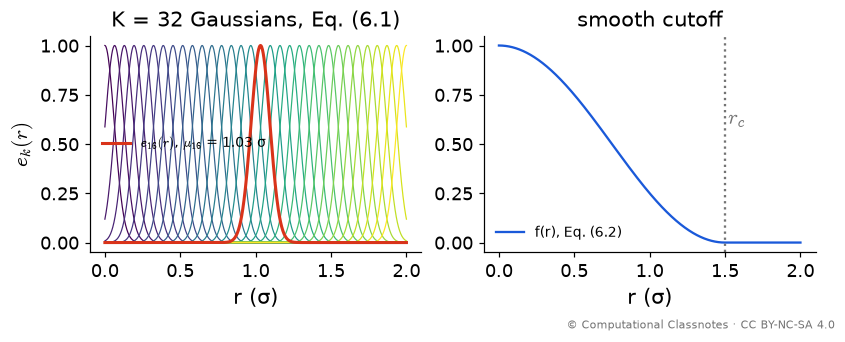

In [10]:
# c.9
# the radial basis, Eq. (6.1), and the envelope, Eq. (6.2)
from polymer_nn.models import GaussianRBF, cosine_envelope
rb = GaussianRBF(32, 2.0); rgrid = torch.linspace(0, 2.0, 801)
E_r = rb(rgrid).numpy(); f_r = cosine_envelope(rgrid, 1.5).numpy()
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.25, wHalf * 1.05))
for k in range(0, 32, 1): ax[0].plot(rgrid, E_r[:, k], lw=0.8, color=plt.cm.viridis(k / 31))
ax[0].plot(rgrid, E_r[:, 16], color=red, lw=2, label=r"$e_{16}(r)$, $\mu_{16}$ = %.2f σ" % (16 * 2 / 31))
ax[0].set(xlabel="r (σ)", ylabel=r"$e_k(r)$", title="K = 32 Gaussians, Eq. (6.1)"); ax[0].legend(fontsize=9)
ax[1].plot(rgrid, f_r, color=blue, label="f(r), Eq. (6.2)"); ax[1].axvline(1.5, color=grey, ls=":")
ax[1].text(1.52, 0.6, r"$r_c$", color=grey); ax[1].set(xlabel="r (σ)", title="smooth cutoff"); ax[1].legend(fontsize=9)
fig.tight_layout(); savefig(fig, "fig4_rbf_envelope"); plt.show()

*Figure 4. Left: the 32 Gaussians of Eq. (6.1); a distance r becomes the vector of their 32 values at r. Right: the envelope f(r), which is 1 at r = 0 and falls with zero slope to 0 at r_c = 1.5 σ.*

,largest change of E between neighbouring points (Δr = 0.001 σ),largest change of the force on bead 5
with the envelope f(r),6.5 × 10⁻⁶,4.9 × 10⁻⁵
hard cutoff (f = 1),5.2 × 10⁻³,4.8 × 10⁻³


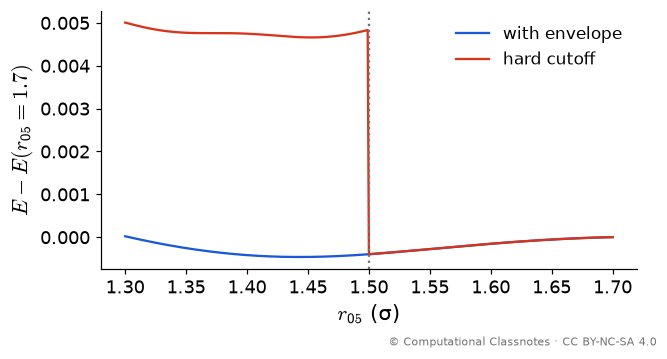

In [11]:
# c.10
# Theorem 6: bead 5 of the folded chain moves away from bead 0 through r_c, with and without the envelope
import polymer_nn.models as M
torch.manual_seed(7); mdl = InvariantGNN(hidden=16, layers=2).double().eval()
def scan(use_env):
    old = M.edge_envelope
    if not use_env:
        M.edge_envelope = lambda r, t, c: torch.ones_like(r)    # a hard cutoff: messages switch on at full size
    out = []
    try:
        for d05 in np.linspace(1.3, 1.7, 401):
            x = xs.copy(); u = (x[5] - x[0]) / np.linalg.norm(x[5] - x[0]); x[5] = x[0] + d05 * u
            dd = to_data(x); dd.pos = torch.tensor(x, dtype=torch.float64); e, f = mdl(dd)
            out.append((d05, float(e.detach()), float(f[5].detach() @ torch.tensor(u))))
    finally:
        M.edge_envelope = old
    return np.array(out)
S1, S0 = scan(True), scan(False)
jump = lambda S: np.abs(np.diff(S[:, 1])).max()
table([["", "largest change of E between neighbouring points (Δr = 0.001 σ)", "largest change of the force on bead 5"],
       ["with the envelope f(r)", sci(jump(S1)), sci(np.abs(np.diff(S1[:, 2])).max())],
       ["hard cutoff (f = 1)", sci(jump(S0)), sci(np.abs(np.diff(S0[:, 2])).max())]], "Table 8. Theorem 6, checked")
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.1))
ax.plot(S1[:, 0], S1[:, 1] - S1[-1, 1], color=blue, label="with envelope"); ax.plot(S0[:, 0], S0[:, 1] - S0[-1, 1], color=red, label="hard cutoff")
ax.axvline(1.5, color=grey, ls=":"); ax.set(xlabel=r"$r_{05}$ (σ)", ylabel=r"$E - E(r_{05} = 1.7)$"); ax.legend()
fig.tight_layout(); savefig(fig, "fig5_cutoff"); plt.show()

*Figure 5. The energy of the folded chain (random weights) as bead 5 moves away from bead 0 through the cutoff r_c = 1.5 σ (dotted). With the envelope the curve is smooth; with a hard cutoff the energy jumps when the edge disappears. Such a jump would put an infinite force into a simulation, or, in practice, a sudden kick at each crossing.*

## 7. Forces from an energy, and why that conserves energy

The force on bead i is minus the gradient of the energy with respect to its position:

$$
F_i(x) = -\frac{\partial E}{\partial x_i}(x) , \qquad i = 1, \dots, N \tag{7.1}
$$

The networks compute E, and PyTorch's automatic differentiation computes all N gradients in one backward pass (Theorem 1, now with respect to the inputs). Newton's equations with these forces, for unit masses, are dx_i/dt = v_i, dv_i/dt = F_i. The total energy is

$$
H(x, v) = \sum_i \tfrac12 |v_i|^{2} + E(x) \tag{7.2}
$$

**Theorem 8 (energy conservation).** Along every solution of Newton's equations with the forces of Eq. (7.1), H is constant. If instead the forces are any other vector field G(x) (predicted directly, say), dH/dt = Σ_i v_i·(G_i + ∂E/∂x_i). This is in general not zero: a G with curl does work around closed loops, and no function E can then make H constant.

*Proof.* dH/dt = Σ_i v_i·dv_i/dt + Σ_i ∂E/∂x_i · dx_i/dt = Σ_i v_i·F_i + Σ_i ∂E/∂x_i·v_i = 0 by Eq. (7.1). For a general G, the work around a closed loop C is ∮_C G·dx, which by Stokes' theorem is the flux of curl G through a surface bounded by C. It vanishes for all loops exactly when G is a gradient. ∎

Real simulations use a time step, so H is conserved only approximately, but for velocity Verlet the error stays bounded and shrinks as Δt² (Theorem 10). Cell c.11 makes the difference visible on a two-dimensional example. A particle moves in the potential E(x, y) = (x² + y²)²/4, once with F = −∇E and once with a "learned" force that has a small error with curl, G = −∇E + 0.05 (−y, x).

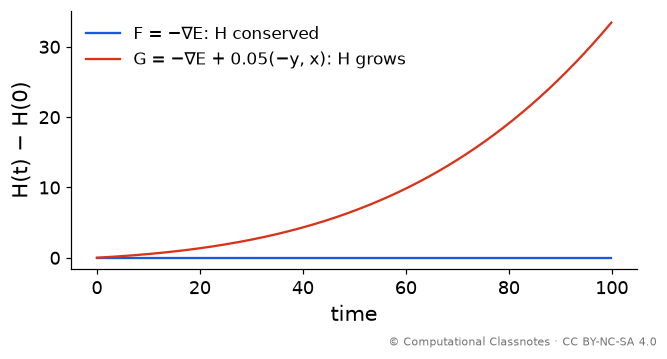

after t = 100: |ΔH| = 5.5e-07 (gradient force), 33.43 (force with curl)


In [12]:
# c.11
# Theorem 8: a conservative force keeps H; a slightly wrong force with curl does work around every loop
def run(force, steps=20000, dt=0.005):
    x, v = np.array([1.0, 0.0]), np.array([0.0, 0.8]); Hs = []
    Epot = lambda x: (x @ x) ** 2 / 4
    f = force(x)
    for s in range(steps):
        v = v + 0.5 * dt * f; x = x + dt * v; f = force(x); v = v + 0.5 * dt * f     # velocity Verlet, Eq. (9.1)
        if s % 20 == 0: Hs.append(0.5 * v @ v + Epot(x))
    return np.arange(len(Hs)) * 20 * dt, np.array(Hs)
gradF = lambda x: -(x @ x) * x                               # -grad E
curlF = lambda x: -(x @ x) * x + 0.05 * np.array([-x[1], x[0]])
t1, H1 = run(gradF); t2, H2 = run(curlF)
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.1))
ax.plot(t1, H1 - H1[0], color=blue, label="F = −∇E: H conserved"); ax.plot(t2, H2 - H2[0], color=red, label="G = −∇E + 0.05(−y, x): H grows")
ax.set(xlabel="time", ylabel="H(t) − H(0)"); ax.legend(); fig.tight_layout(); savefig(fig, "fig6_conservation"); plt.show()
print(f"after t = {t1[-1]:.0f}: |ΔH| = {abs(H1[-1] - H1[0]):.1e} (gradient force), {abs(H2[-1] - H2[0]):.2f} (force with curl)")

*Figure 6. The same particle, the same integrator, two force fields that differ by 5% of a curl term. With F = −∇E the total energy stays constant to within the small, bounded integration error. With the curl term the force does work on every turn and the particle heats up without bound. This is why our networks predict an energy and differentiate it.*

## 8. Force matching: what the training actually learns

The training loss of `polymer_nn.train` (Eq. (T1) there) compares predicted and reference forces on M reference configurations $x^{(s)}$ drawn from the Boltzmann distribution p(x) ∝ exp(−E(x)/k_BT):

$$
\chi^{2}[\hat E] = \frac{1}{3NM} \sum_{s=1}^{M} \sum_{i=1}^{N} \bigl| -\nabla_i \hat E(x^{(s)}) - F_i^{\mathrm{ref}}(x^{(s)}) \bigr|^{2} \tag{8.1}
$$

For the fine-grained chain the reference force is exactly −∇E, so χ² = 0 when Ê = E plus a constant, and the minimum is the true energy. The interesting case is *coarse-graining*. There a model sees only some collective coordinates S = s(x), for example the centres of groups of beads, and the reference "force" on S is the mapped fine-grained force F_S(x), which also depends on the hidden coordinates. Then no function of S alone can match the reference exactly.

**Theorem 9 (force matching gives the mean force [izvekov2005, noid2008]).** Among all functions of S, the one that minimises the expected squared error E_p|G(s(x)) − F_S(x)|² is the conditional mean G*(S) = E_p[F_S | s(x) = S]. When F_S is the mapped force, G* = −∇_S W, where W is the potential of mean force

$$
W(S) = -k_B T \ln \int \delta\bigl(s(x) - S\bigr) \, e^{-E(x)/k_B T} \, dx \tag{8.2}
$$

so the coarse model with energy W reproduces the exact distribution of S:

$$
p(S) \propto e^{-W(S)/k_B T} \tag{8.3}
$$

*Proof (first part).* For any G, E|G(S) − F_S|² = E|G(S) − G*(S)|² + E|G*(S) − F_S|². The cross term vanishes because E[F_S − G*(S) | S] = 0. The second term does not depend on G, so the minimum is at G = G*. The identity G* = −∇W follows by differentiating Eq. (8.2) under the integral sign, for a linear mapping s with the mapped force defined as in `polymer_nn.coarse_grain`, Eq. (C2) [noid2008]. ∎

Cell c.12 checks the theorem in two dimensions. Take E(s, q) = (s² − 1)² + 2(q − 0.5 s)² + 0.3 q⁴, keep s and integrate out q. A least-squares fit of the force on s at Boltzmann-distributed points, using functions of s only, reproduces −dW/ds, which is computed independently from Eq. (8.2) by quadrature:

$$
-\frac{dW}{ds} = \Bigl\langle -\frac{\partial E}{\partial s} \Bigr\rangle_{q \,|\, s} \tag{8.4}
$$

max |force-matching fit − (−dW/ds)| where p(s) > 1e-4: 1.65e-04


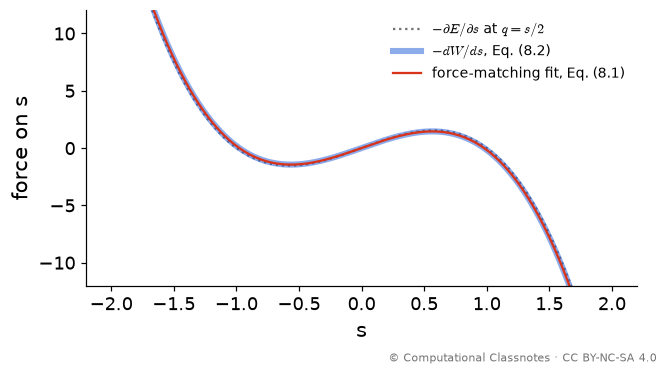

In [13]:
# c.12
# Theorem 9 in 2D: the force-matching fit equals the mean force -dW/ds of Eq. (8.2)
kT = 1.0
E2 = lambda s, q: (s**2 - 1)**2 + 2 * (q - 0.5 * s)**2 + 0.3 * q**4
dEds = lambda s, q: 4 * s * (s**2 - 1) - 2 * (q - 0.5 * s)
sg, qg = np.linspace(-2, 2, 801), np.linspace(-4, 4, 1601)
S, Q = np.meshgrid(sg, qg, indexing="ij"); w = np.exp(-E2(S, Q) / kT)       # Boltzmann weights on a grid
W = -kT * np.log(w.sum(1))                                                 # Eq. (8.2) by quadrature (up to a constant)
mean_force_W = -np.gradient(W, sg)                                         # -dW/ds
# force matching: weighted least squares of -dE/ds on polynomials in s (degree 9), Eq. (8.1)
Phi = np.vander(S.ravel(), 10); y = -dEds(S, Q).ravel(); ww = w.ravel()
coef = np.linalg.lstsq(Phi * np.sqrt(ww)[:, None], y * np.sqrt(ww), rcond=None)[0]
fit = np.vander(sg, 10) @ coef
ps = w.sum(1); ps /= ps.sum(); inside = ps > 1e-4                         # compare where p(s) is not tiny
print(f"max |force-matching fit − (−dW/ds)| where p(s) > 1e-4: {np.abs(fit - mean_force_W)[inside].max():.2e}")
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.15))
ax.plot(sg, -dEds(sg, 0.5 * sg), color=grey, ls=":", label=r"$-\partial E/\partial s$ at $q = s/2$")
ax.plot(sg, mean_force_W, color=blue, lw=4, alpha=.5, label=r"$-dW/ds$, Eq. (8.2)"); ax.plot(sg, fit, color=red, label="force-matching fit, Eq. (8.1)")
ax.set(xlabel="s", ylabel="force on s", ylim=(-12, 12)); ax.legend(fontsize=9); fig.tight_layout(); savefig(fig, "fig7_force_matching"); plt.show()

*Figure 7. Coarse-graining a two-dimensional system to its coordinate s. The least-squares fit of the force on s, using functions of s only (red), lands on the mean force −dW/ds computed from Eq. (8.2) by quadrature (thick blue), not on the force at any particular value of the hidden coordinate (dotted). This is what a coarse-grained network trained by force matching learns.*

## 9. Integrators: from forces to trajectories

### 9.1 Velocity Verlet (constant energy)

With time step Δt and unit masses [swope1982]:

$$
v \leftarrow v + \tfrac12 \Delta t\, F(x) , \qquad x \leftarrow x + \Delta t\, v , \qquad v \leftarrow v + \tfrac12 \Delta t\, F(x) \tag{9.1}
$$

**Theorem 10 (shadow energy [hairer2003]).** Velocity Verlet is symplectic and time-reversible. For smooth forces it conserves exactly, up to exponentially small terms over very long times, a modified energy H̃ = H + O(Δt²). Hence the true energy H fluctuates by O(Δt²) and does not drift:

$$
\max_{t \le T} |H(t) - H(0)| = O(\Delta t^{2}) \quad \text{over long times } T \tag{9.2}
$$

(The theorem needs smooth forces, which is a second reason for the smooth envelope of section 6.2.)

### 9.2 Langevin dynamics (constant temperature) and BAOAB

To sample the Boltzmann distribution at temperature T, friction γ and random kicks are added:

$$
dx = v\, dt , \qquad dv = F(x)\, dt - \gamma v \, dt + \sqrt{2 \gamma k_B T}\, dW_t \tag{9.3}
$$

whose stationary distribution is p(x, v) ∝ exp(−H(x, v)/k_BT). The reference data of this repository come from OpenMM's `LangevinMiddleIntegrator` [zhang2019]. The learned-force runs use the BAOAB splitting [leimkuhler2013] (`polymer_nn.md.langevin_batched`): half kick B, half drift A, then the exact solution O of the friction-plus-noise part, then A and B again,

$$
\mathrm O: \quad v \leftarrow e^{-\gamma \Delta t} v + \sqrt{(1 - e^{-2\gamma\Delta t}) k_B T}\; \xi , \qquad \xi \sim \mathcal N(0, 1) \tag{9.4}
$$

which samples the configurational distribution with an error of order Δt². Cell c.13 checks Eq. (9.2) on a harmonic oscillator; cell c.14 checks that BAOAB samples a double-well potential correctly.

In [14]:
# c.13
# Eq. (9.2): the energy error of velocity Verlet scales as dt^2 (harmonic oscillator E = x^2/2)
rows = [["Δt", "max |H(t) − H(0)| over t ≤ 200", "ratio to the previous Δt"]]; prev = None; errs = []
dts = [0.2, 0.1, 0.05, 0.025, 0.0125]
for dt in dts:
    x, v = 1.0, 0.0; H0 = 0.5; err = 0
    for s in range(int(200 / dt)):
        v -= 0.5 * dt * x; x += dt * v; v -= 0.5 * dt * x
        err = max(err, abs(0.5 * v * v + 0.5 * x * x - H0))
    rows.append([dt, sci(err), "" if prev is None else f"{prev / err:.3f}"]); prev = err; errs.append(err)
slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
table(rows + [["fitted exponent p in error ∝ Δt^p", f"{slope:.3f}", "(Theorem 10: p = 2)"]], "Table 9. Velocity Verlet, Eq. (9.2)")

Δt,max |H(t) − H(0)| over t ≤ 200,ratio to the previous Δt
0.2,5 × 10⁻³,
0.1,1.2 × 10⁻³,4.000
0.05,3.1 × 10⁻⁴,4.000
0.025,7.8 × 10⁻⁵,4.000
0.0125,2 × 10⁻⁵,4.000
fitted exponent p in error ∝ Δt^p,2.000,(Theorem 10: p = 2)


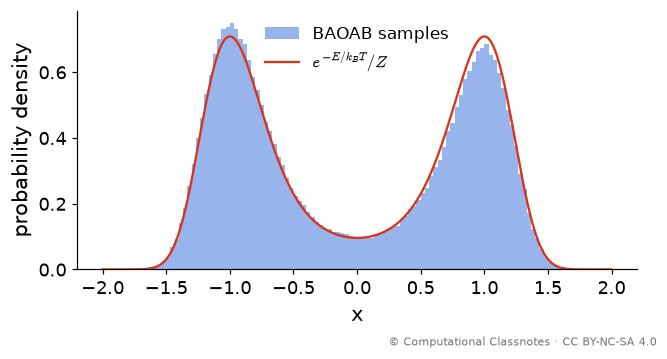

mean |histogram − Boltzmann| = 0.011 (density ~ 0.5–1 at the wells)


In [15]:
# c.14
# BAOAB, Eqs. (9.3)-(9.4), samples p(x) ∝ exp(-E/kT) for the double well E = (x^2 - 1)^2 at kT = 0.5
kT, gam, dt, steps = 0.5, 1.0, 0.05, 400000
Ew = lambda x: (x**2 - 1)**2; Fw = lambda x: -4 * x * (x**2 - 1)
x, v = 1.0, 0.0; c1 = np.exp(-gam * dt); c2 = np.sqrt((1 - c1**2) * kT)
xi = rng.normal(size=steps); xs_l = np.empty(steps); f = Fw(x)
for s in range(steps):
    v += 0.5 * dt * f; x += 0.5 * dt * v; v = c1 * v + c2 * xi[s]; x += 0.5 * dt * v; f = Fw(x); v += 0.5 * dt * f
    xs_l[s] = x
grid = np.linspace(-2, 2, 401); pb = np.exp(-Ew(grid) / kT); pb /= np.trapezoid(pb, grid)
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.1))
ax.hist(xs_l, bins=120, range=(-2, 2), density=True, color=blue, alpha=.45, label="BAOAB samples")
ax.plot(grid, pb, color=red, label=r"$e^{-E/k_BT}/Z$")
ax.set(xlabel="x", ylabel="probability density"); ax.legend(); fig.tight_layout(); savefig(fig, "fig8_baoab"); plt.show()
hist, edges = np.histogram(xs_l, bins=80, range=(-2, 2), density=True); mid = (edges[1:] + edges[:-1]) / 2
pm = np.exp(-Ew(mid) / kT) / np.trapezoid(pb * 0 + np.exp(-Ew(grid) / kT), grid)
print(f"mean |histogram − Boltzmann| = {np.mean(np.abs(hist - pm)):.3f} (density ~ 0.5–1 at the wells)")

*Figure 8. Langevin dynamics with the BAOAB splitting: the histogram of 400 000 positions in a double well agrees with the Boltzmann distribution, including the barrier region the particle crosses only occasionally.*

## 10. Polymer physics: what the learned chain must reproduce

### 10.1 The ideal chain

Let the bonds $b_k = x_{k+1} - x_k$, k = 1, …, N − 1, be independent random vectors with ⟨b_k⟩ = 0 and ⟨|b_k|²⟩ = b². Then the end-to-end vector R_e = Σ_k b_k satisfies

$$
\langle |R_e|^{2} \rangle = \sum_{k,l} \langle b_k \cdot b_l \rangle = (N-1)\, b^{2} \tag{10.1}
$$

since the cross terms average to 0. The size of a chain grows as the square root of its length: this is the random walk, with ν = 1/2.

The *radius of gyration* (the root-mean-square distance of the beads from their centre of mass; `polymer_nn.analysis`, Eq. (A1)) has an exact formula.

**Theorem 11a (radius of gyration of an ideal chain).**

$$
\langle R_g^{2} \rangle = \frac{1}{2N^{2}} \sum_{i,j} \langle |x_i - x_j|^{2} \rangle = \frac{b^{2}}{2N^{2}} \sum_{i,j=1}^{N} |i - j| = \frac{(N^{2} - 1)\, b^{2}}{6N} \tag{10.2}
$$

*Proof.* The first equality is the identity Σ_i |x_i − x_cm|² = $(1/2N) \sum_{i,j} |x_i - x_j|^2$. The second is Eq. (10.1) applied to the sub-chain between i and j, which has |i − j| bonds. The double sum is evaluated by SymPy in cell c.15. ∎

### 10.2 The self-avoiding chain and Flory's argument

Beads cannot overlap, so a real chain swells. Flory's estimate balances two free energies, in units of k_BT, for a chain of size R: an elastic (entropic) cost of stretching, R²/(N b²), and the repulsion between the N beads packed into a volume R³, at density N/R³, giving about v N²/R³ with an excluded volume v:

$$
\frac{\mathcal F(R)}{k_B T} = \frac{R^{2}}{N b^{2}} + \frac{v N^{2}}{R^{3}} \tag{10.3}
$$

Setting d𝓕/dR = 0 gives

$$
R^{5} = \tfrac32\, v\, b^{2} N^{3} \quad \Longrightarrow \quad R \propto N^{3/5} , \qquad \nu_{\mathrm{Flory}} = \frac{3}{5} \tag{10.4}
$$

The exact value from large-scale Monte Carlo is a little smaller [clisby2010]:

$$
R_g \propto N^{\nu} , \qquad \nu = 0.587597(7) \tag{10.5}
$$

The power law holds for long chains. Short chains also feel corrections, $R_g = b N^{\nu} (1 + a N^{-\Delta} + \dots)$ with Δ ≈ 0.5, so a fit over N = 16–128 gives an *effective* exponent that need not equal 0.588. The learned models are therefore compared with the reference simulations at the same N (notebooks 02 and 04).

### 10.3 Pivot Monte Carlo

**Theorem 11 (the pivot algorithm samples the Boltzmann distribution [lal1969, madras1988]).** Pick a bead k and a rotation R uniformly at random, rotate one end of the chain about x_k, and accept with probability $\min(1, e^{-\Delta E/k_BT})$. This leaves the distribution $\propto e^{-E/k_BT}$ of chains with the given bond lengths invariant.

*Proof.* The proposal is symmetric: the move with (k, R) is undone by (k, R⁻¹), and R⁻¹ is as likely as R under the uniform (Haar) distribution of rotations. A symmetric proposal with the Metropolis acceptance satisfies detailed balance, π(a) P(a → b) = π(b) P(b → a), and detailed balance implies that π is invariant. Pivots of the ideal chain (no ΔE) leave the bond vectors independent and uniformly oriented, which is the random walk of section 10.1. ∎

### 10.4 The Kremer–Grest model

For reference, the potentials of the reference simulations (`polymer_nn.sim`, Eqs. (S1)–(S2)), in units σ = ε = 1:

$$
U_{\mathrm{FENE}}(r) = -\tfrac12 k R_0^{2} \ln\bigl(1 - (r/R_0)^{2}\bigr) , \qquad U_{\mathrm{WCA}}(r) = \bigl[4(r^{-12} - r^{-6}) + 1\bigr]\, \Theta(2^{1/6} - r) \tag{10.6}
$$

$$
E(x) = \sum_{i=1}^{N-1} U_{\mathrm{FENE}}(|x_{i+1} - x_i|) + \sum_{i<j} U_{\mathrm{WCA}}(|x_j - x_i|) \tag{10.7}
$$

with k = 30 and R₀ = 1.5. Cell c.15 derives Eq. (10.2) with SymPy and checks it on random walks. Cell c.16 solves Flory's Eq. (10.3) symbolically. Cell c.17 checks Theorem 11 by running pivots on an ideal chain.

In [16]:
# c.15
# Eq. (10.2) by SymPy, then checked on 20 000 random walks per N
import sympy as sp
N_, i_, j_, b_ = sp.symbols("N i j b", positive=True, integer=True)
double_sum = 2 * sp.summation(sp.summation(j_ - i_, (j_, i_ + 1, N_)), (i_, 1, N_))     # Σ_{i,j} |i - j|
Rg2 = sp.simplify(b_**2 / (2 * N_**2) * double_sum)
print("Σ_{i,j} |i − j| =", sp.factor(double_sum), "   ⟨Rg²⟩ =", sp.factor(Rg2))
from polymer_nn.analysis import radius_of_gyration
rows = [["N", "⟨Rg²⟩ from 20 000 random walks", "Eq. (10.2)", "relative difference"]]
for N in (8, 32, 128):
    steps_ = rng.normal(size=(20000, N - 1, 3)); steps_ /= np.linalg.norm(steps_, axis=-1, keepdims=True)   # b = 1
    walks = np.concatenate([np.zeros((20000, 1, 3)), np.cumsum(steps_, axis=1)], axis=1)
    sim_ = np.mean(radius_of_gyration(walks) ** 2); th = float(Rg2.subs({N_: N, b_: 1}))
    rows.append([N, f"{sim_:.4f}", f"{th:.4f}", f"{(sim_ - th) / th:+.4f}"])
table(rows, "Table 10. The ideal chain, Theorem 11a")

Σ_{i,j} |i − j| = N*(N - 1)*(N + 1)/3    ⟨Rg²⟩ = b**2*(N - 1)*(N + 1)/(6*N)


N,⟨Rg²⟩ from 20 000 random walks,Eq. (10.2),relative difference
8,1.3114,1.3125,-0.0008
32,5.3215,5.3281,-0.0012
128,21.1704,21.3320,-0.0076


In [17]:
# c.16
# Flory's argument, Eqs. (10.3)-(10.4), solved symbolically
R, Nf, v_, bb = sp.symbols("R N v b", positive=True)
Fl = R**2 / (Nf * bb**2) + v_ * Nf**2 / R**3
Rstar = sp.solve(sp.diff(Fl, R), R)[0]
nu_F = sp.limit(sp.log(Rstar) / sp.log(Nf), Nf, sp.oo)
print("dF/dR = 0  ⇒  R* =", sp.simplify(Rstar), "   ν_Flory = lim log R*/log N =", nu_F)

dF/dR = 0  ⇒  R* = 2**(4/5)*3**(1/5)*N**(3/5)*b**(2/5)*v**(1/5)/2    ν_Flory = lim log R*/log N = 3/5


"chain, N = 64, bonds 1 σ",⟨Rg²⟩ from pivot MC,reference
ideal (no excluded volume),10.86,"10.66, Eq. (10.2)"
self-avoiding (WCA),32.03,larger: the chain swells


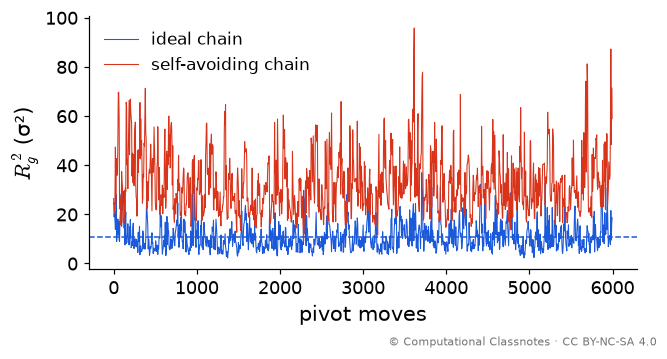

In [18]:
# c.17
# Theorem 11: pivots of an ideal chain (no excluded volume) reproduce Eq. (10.2); with excluded volume the chain swells
from polymer_nn.sim import pivot_mc, initial_positions
Np = 64; x0 = initial_positions(Np, rng, bond=1.0)
_, tr_ideal = pivot_mc(x0, 6000, rng, excluded_volume=False, record_every=5)
_, tr_saw = pivot_mc(x0, 6000, rng, excluded_volume=True, record_every=5)
th = float(Rg2.subs({N_: Np, b_: 1}))
table([["chain, N = 64, bonds 1 σ", "⟨Rg²⟩ from pivot MC", "reference"],
       ["ideal (no excluded volume)", f"{np.mean(tr_ideal[200:]**2):.2f}", f"{th:.2f}, Eq. (10.2)"],
       ["self-avoiding (WCA)", f"{np.mean(tr_saw[200:]**2):.2f}", "larger: the chain swells"]], "Table 11. Pivot Monte Carlo, Theorem 11")
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.1))
ax.plot(np.arange(len(tr_ideal)) * 5, tr_ideal**2, color=blue, lw=0.7, label="ideal chain")
ax.plot(np.arange(len(tr_saw)) * 5, tr_saw**2, color=red, lw=0.7, label="self-avoiding chain")
ax.axhline(th, color=blue, ls="--", lw=1); ax.set(xlabel="pivot moves", ylabel=r"$R_g^2$ (σ²)"); ax.legend()
fig.tight_layout(); savefig(fig, "fig9_pivot"); plt.show()

*Figure 9. R_g² of a 64-bead chain during pivot Monte Carlo. The ideal chain fluctuates around the exact value of Eq. (10.2) (dashed); the self-avoiding chain swells to a larger size. Each accepted pivot changes the overall shape, so R_g decorrelates within a few moves.*

## Appendix A. The formulas in one place

- **Neuron, layer, network:** z = w·x + b, a = φ(z), Eq. (1.1); SiLU(z) = zσ(z), Eq. (1.2); z = Wx + b, Eq. (1.4); Z = XWᵀ + 1bᵀ, Eq. (1.5); $a^l = \varphi(W^l a^{l-1} + b^l)$, Eq. (1.6).
- **Training:** loss Eq. (2.1); $\delta^L$, $\delta^l = ((W^{l+1})^{\mathsf T}\delta^{l+1}) \odot \varphi'(z^l)$, $\partial L/\partial W^l = \delta^l (a^{l-1})^{\mathsf T}$, Eqs. (2.2)–(2.4); gradient descent Eq. (2.5); Adam Eq. (2.6).
- **Graph:** nodes = beads with x_i and z_i; edges = bonds (τ = 1) and pairs with r_ij < r_c (τ = 0), Eq. (3.2).
- **Message passing:** m_ij = M(h_i, h_j, e_ij), sum over 𝒩(i), h_i ← U(h_i, m̄_i), E = Σ_i R(h_i), Eqs. (4.1)–(4.4); invariant under renumbering, Theorem 3.
- **Symmetry:** E(Rx + t) = E(x), F(Rx + t) = R F(x), ΣF_i = 0 and Σ x_i × F_i = 0, Eqs. (5.2)–(5.4); distances suffice, Theorems 4–5.
- **The networks:** radial basis Eq. (6.1); envelope Eq. (6.2), Theorem 6; SchNet-style layer Eqs. (6.3)–(6.5); EGNN layer Eqs. (6.6)–(6.8), Theorem 7; readout Eq. (6.9). In the code: `polymer_nn.models`, Eqs. (M1)–(M10).
- **Forces:** F = −∇E, Eq. (7.1), conserves H = K + E, Eq. (7.2), Theorem 8.
- **Force matching:** Eq. (8.1); the minimiser is the mean force −∇W, Eqs. (8.2)–(8.4), Theorem 9.
- **Integrators:** velocity Verlet Eq. (9.1), energy error O(Δt²), Eq. (9.2), Theorem 10; Langevin Eq. (9.3); BAOAB Eq. (9.4).
- **Polymers:** ⟨R_e²⟩ = (N − 1)b², Eq. (10.1); ⟨R_g²⟩ = (N² − 1)b²/(6N), Eq. (10.2); Flory ν = 3/5, Eqs. (10.3)–(10.4); ν = 0.5876, Eq. (10.5); pivot MC, Theorem 11; Kremer–Grest, Eqs. (10.6)–(10.7).

## References

- [1] D. O Shayda, N. Hoshino, S Shape Functions Theory, Computational Classnotes (2026), github.com/lossofgenerality/neural-networks-things.
- [2] D. O Shayda, N. Hoshino, Feedforward Neural Networks: The Algebra and the Computing, Computational Classnotes (2026), github.com/lossofgenerality/neural-networks-things.
- [rumelhart1986] D. E. Rumelhart, G. E. Hinton, R. J. Williams, Learning representations by back-propagating errors, Nature 323 (1986) 533–536. doi:10.1038/323533a0
- [cybenko1989] G. Cybenko, Approximation by superpositions of a sigmoidal function, Math. Control Signals Systems 2 (1989) 303–314. doi:10.1007/BF02551274
- [elfwing2018] S. Elfwing, E. Uchibe, K. Doya, Sigmoid-weighted linear units for neural network function approximation in reinforcement learning, Neural Networks 107 (2018) 3–11. doi:10.1016/j.neunet.2017.12.012
- [kingma2015] D. P. Kingma, J. Ba, Adam: A method for stochastic optimization, ICLR 2015, arXiv:1412.6980.
- [gilmer2017] J. Gilmer et al., Neural message passing for quantum chemistry, ICML 2017, PMLR 70, 1263–1272.
- [fey2019] M. Fey, J. E. Lenssen, Fast graph representation learning with PyTorch Geometric, arXiv:1903.02428 (2019).
- [schutt2017] K. T. Schütt et al., SchNet: a continuous-filter convolutional neural network for modeling quantum interactions, NeurIPS 30 (2017).
- [schutt2018] K. T. Schütt et al., SchNet – a deep learning architecture for molecules and materials, J. Chem. Phys. 148 (2018) 241722. doi:10.1063/1.5019779
- [satorras2021] V. G. Satorras, E. Hoogeboom, M. Welling, E(n) equivariant graph neural networks, ICML 2021, PMLR 139, 9323–9332.
- [izvekov2005] S. Izvekov, G. A. Voth, A multiscale coarse-graining method for biomolecular systems, J. Phys. Chem. B 109 (2005) 2469–2473. doi:10.1021/jp044629q
- [noid2008] W. G. Noid et al., The multiscale coarse-graining method. I, J. Chem. Phys. 128 (2008) 244114. doi:10.1063/1.2938860
- [swope1982] W. C. Swope, H. C. Andersen, P. H. Berens, K. R. Wilson, J. Chem. Phys. 76 (1982) 637–649. doi:10.1063/1.442716
- [hairer2003] E. Hairer, C. Lubich, G. Wanner, Geometric numerical integration illustrated by the Störmer–Verlet method, Acta Numerica 12 (2003) 399–450. doi:10.1017/S0962492902000144
- [zhang2019] Z. Zhang, X. Liu, K. Yan, M. E. Tuckerman, J. Liu, J. Phys. Chem. A 123 (2019) 6056–6079. doi:10.1021/acs.jpca.9b02771
- [leimkuhler2013] B. Leimkuhler, C. Matthews, Rational construction of stochastic numerical methods for molecular sampling, Appl. Math. Res. Express 2013 (2013) 34–56. doi:10.1093/amrx/abs010
- [clisby2010] N. Clisby, Accurate estimate of the critical exponent ν for self-avoiding walks via a fast implementation of the pivot algorithm, Phys. Rev. Lett. 104 (2010) 055702. doi:10.1103/PhysRevLett.104.055702
- [lal1969] M. Lal, "Monte Carlo" computer simulation of chain molecules. I, Mol. Phys. 17 (1969) 57–64. doi:10.1080/00268976900100781
- [madras1988] N. Madras, A. D. Sokal, The pivot algorithm, J. Stat. Phys. 50 (1988) 109–186. doi:10.1007/BF01022990
- [kremer1990] K. Kremer, G. S. Grest, Dynamics of entangled linear polymer melts, J. Chem. Phys. 92 (1990) 5057–5086. doi:10.1063/1.458541
- The complete bibliography, with every source used in the repository: `docs/REFERENCES.md` and `docs/REFERENCES.pdf`.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>